# Analysis: how do prospective students use the placement website?

Reads only the **cleaned** files in `outputs/` (made by `Data_Cleaner_SCR.py` and `Data_Metrics_SCR.py`). The raw data is not touched here.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../reports/figures", exist_ok=True)   # where the charts are saved
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

sessions = pd.read_csv("../outputs/session_facts.csv", parse_dates=["session_date"])
events = pd.read_csv("../outputs/events_clean.csv")
campaigns = pd.read_csv("../data/raw/campaigns.csv", parse_dates=["start_date", "end_date"])

sessions["month"] = sessions["session_date"].dt.to_period("M").astype(str)
sessions["campaign_id"] = sessions["campaign_id"].fillna("none")

eligible = sessions[~sessions["is_suspected_automated"]].copy()
elig_events = events[events["session_id"].isin(eligible["session_id"])].copy()
page_views = elig_events[elig_events["event_name"] == "page_view"]

print(len(sessions), "tracked sessions |", len(eligible), "eligible sessions |", len(elig_events), "events from eligible sessions")

20748 tracked sessions | 19398 eligible sessions | 44016 events from eligible sessions


# Question 1: How does traffic change over time? Which pages and acquisition channels contribute to those changes?

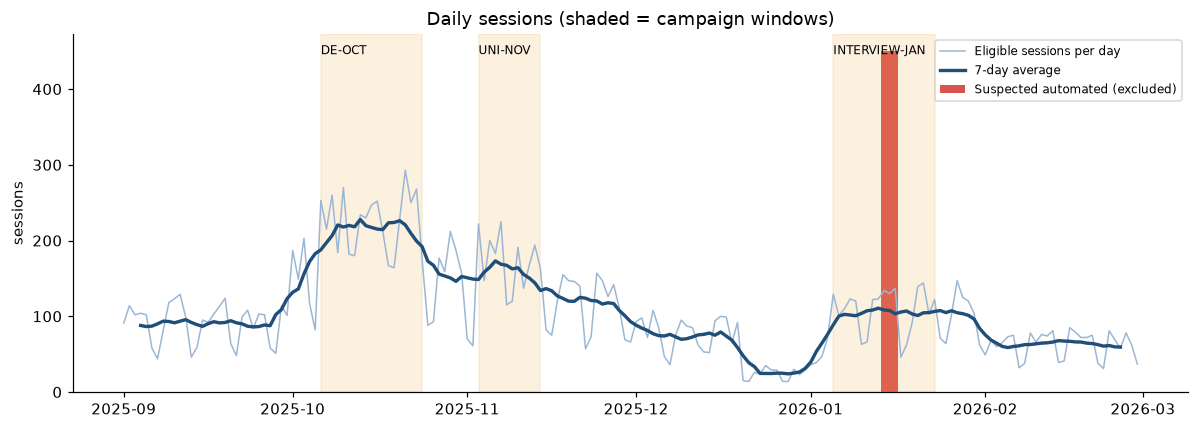

In [2]:
daily = eligible.groupby("session_date").size()
daily_auto = sessions[sessions["is_suspected_automated"]].groupby("session_date").size()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.values, color="#9bb7d4", lw=1, label="Eligible sessions per day")
ax.plot(daily.index, daily.rolling(7, center=True).mean(), color="#1f4e79", lw=2.2, label="7-day average")
ax.bar(daily_auto.index, daily_auto.values, color="#d9534f", width=1, label="Suspected automated (excluded)")
for _, c in campaigns.iterrows():
    ax.axvspan(c["start_date"], c["end_date"], color="#f0ad4e", alpha=0.18)
    ax.text(c["start_date"], 0.97, c["campaign_id"].replace("CMP-", ""), fontsize=8, va="top", transform=ax.get_xaxis_transform())
ax.set_ylabel("sessions"); ax.set_title("Daily sessions (shaded = campaign windows)"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig("../reports/figures/q1_daily_sessions.png", dpi=150); plt.show()

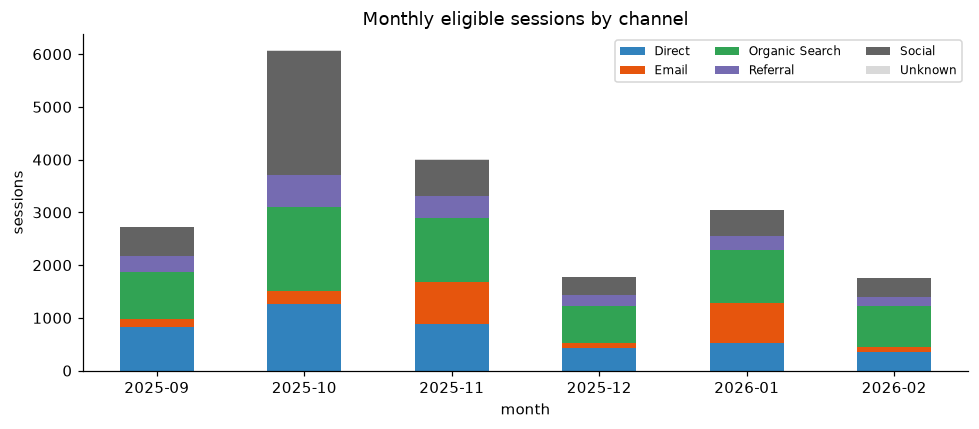

In [3]:
by_channel = eligible.pivot_table(index="month", columns="channel", values="session_id", aggfunc="count").fillna(0)
by_channel.plot(kind="bar", stacked=True, figsize=(9, 4), colormap="tab20c", rot=0)
plt.ylabel("sessions"); plt.title("Monthly eligible sessions by channel"); plt.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.savefig("../reports/figures/q1_channel_by_month.png", dpi=150); plt.show()

In [4]:
# Average sessions PER DAY (I chose this because each month has a different number of days)
days = eligible.groupby("month")["session_date"].nunique()
print("Average eligible sessions per day, by channel")
print(eligible.pivot_table(index="month", columns="channel", values="session_id", aggfunc="count").fillna(0).div(days, axis=0).round(0).astype(int))
print("\nAverage sessions per day, by landing page")
print(eligible.pivot_table(index="month", columns="landing_page_path", values="session_id", aggfunc="count").fillna(0).div(days, axis=0).round(0).astype(int).rename(columns=lambda c: c.replace("/roles/", "role:")))

Average eligible sessions per day, by channel
channel  Direct  Email  Organic Search  Referral  Social  Unknown
month                                                            
2025-09      28      5              30        10      19        0
2025-10      41      8              52        19      76        1
2025-11      30     26              41        14      23        0
2025-12      14      3              22         7      11        0
2026-01      17     24              32         9      16        0
2026-02      13      4              27         6      12        0

Average sessions per day, by landing page
landing_page_path   /  /about  /application  /faqs  /interview-preparation  role:data-engineer  role:marketing-associate  role:software-engineer  role:technical-analyst  /statements  /timeline
month                                                                                                                                                                                         

In [5]:
wd = eligible.groupby(eligible["session_date"].dt.dayofweek >= 5).size() / eligible.groupby(eligible["session_date"].dt.dayofweek >= 5)["session_date"].nunique()
print("average sessions/day: weekdays", round(wd[False]), "| weekends", round(wd[True]))
holiday = eligible[(eligible["session_date"] >= "2025-12-20") & (eligible["session_date"] <= "2026-01-04")]
print("20 Dec - 4 Jan:", round(len(holiday) / 16, 1), "sessions/day")

average sessions/day: weekdays 123 | weekends 67
20 Dec - 4 Jan: 29.8 sessions/day


C:\Users\egorp\AppData\Local\Temp\ipykernel_15472\319906450.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  wd = eligible.groupby(eligible["session_date"].dt.dayofweek >= 5).size() / eligible.groupby(eligible["session_date"].dt.dayofweek >= 5)["session_date"].nunique()
C:\Users\egorp\AppData\Local\Temp\ipykernel_15472\319906450.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  wd = eligible.groupby(eligible["session_date"].dt.dayofweek >= 5).size() / eligible.groupby(eligible["session_date"].dt.dayofweek >= 5)["session_date"].nunique()


**Findings (Q1)**

**October was the busiest month.** Daily sessions were about double those in September, and the busiest weeks were the ones starting 6 and 13 October. Most of the extra visits came from Social (about 76 a day, up from 19 in September) and from people landing on the Data Engineer page (about 50 a day, up from 8). This fits the LinkedIn Data Engineering campaign (CMP-DE-OCT, 6 to 24 October). Direct and Organic Search traffic also went up in October, so the campaign was probably not the only reason.

**Email caused two smaller increases.** Email visits rose in November (the university newsletter, CMP-UNI-NOV) and again in January (the interview-preparation reminder, CMP-INTERVIEW-JAN). In January, about 28 sessions a day landed on /interview-preparation, compared with 3 to 6 a day in other months.

**Traffic was lowest from 20 December to 4 January**, at about 30 sessions a day. It picked up in January, then settled in February at a lower level than in autumn.

**Weekdays are about twice as busy as weekends** (123 against 67 sessions/day).

**Home (`/`)** is the most common landing page every month.

# Question 2: What can we learn about interest in the Data Analyst placement? 

**Important:** the page catalogue has **no Data Analyst page**, and no URL in the data mentions one. The four roles are Data Engineer, Software Engineer, Technical Analyst and Marketing Associate. I will make an assumption and use **Data Engineer as the closest analytical role**.

**How I define interest:** a session is *interested* in a role if it has at least one `page_view` on that role's page. Sessions can view several roles, so role totals are **not additive**. I compare against (a) sessions that viewed other role pages, (b) sessions that viewed no role page, and (c) the same role over time, with and without campaign sessions.

In [6]:
roles = ["Data Engineer", "Technical Analyst", "Software Engineer", "Marketing Associate"]
role_pv = page_views[page_views["page_group"] == "role"]
rows = []
for role in roles:
    ids = set(role_pv.loc[role_pv["placement_role"] == role, "session_id"])
    ev_role = elig_events[elig_events["placement_role"] == role]
    grp = eligible[eligible["session_id"].isin(ids)]
    rows.append({"group": f"viewed {role}", "sessions": len(grp), "share_of_eligible": len(grp) / len(eligible),
                 "apply_click_rate": grp["has_apply_click"].mean(), "email_click_rate": grp["has_email_click"].mean(),
                 "clicked_apply_on_that_page": ev_role.loc[(ev_role["event_name"] == "apply_cta_click"), "session_id"].nunique() / len(grp),
                 "played_video_on_that_page": ev_role.loc[(ev_role["event_name"] == "video_play"), "session_id"].nunique() / len(grp)})
any_role = set(role_pv["session_id"])
no_role = eligible[~eligible["session_id"].isin(any_role)]
rows.append({"group": "viewed no role page", "sessions": len(no_role), "share_of_eligible": len(no_role) / len(eligible),
             "apply_click_rate": no_role["has_apply_click"].mean(), "email_click_rate": no_role["has_email_click"].mean()})
rows.append({"group": "all eligible sessions", "sessions": len(eligible), "share_of_eligible": 1.0,
             "apply_click_rate": eligible["has_apply_click"].mean(), "email_click_rate": eligible["has_email_click"].mean()})
role_table = pd.DataFrame(rows).set_index("group")
role_table.round(3)

,sessions,share_of_eligible,apply_click_rate,email_click_rate,clicked_apply_on_that_page,played_video_on_that_page
group,,,,,,
viewed Data Engineer,4859,0.250,0.197,0.064,0.111,0.104
viewed Technical Analyst,2729,0.141,0.194,0.073,0.126,0.105
viewed Software Engineer,4001,0.206,0.169,0.057,0.114,0.116
viewed Marketing Associate,1874,0.097,0.194,0.070,0.128,0.113
viewed no role page,6459,0.333,0.122,0.088,NaN,NaN
all eligible sessions,19398,1.000,0.165,0.072,NaN,NaN


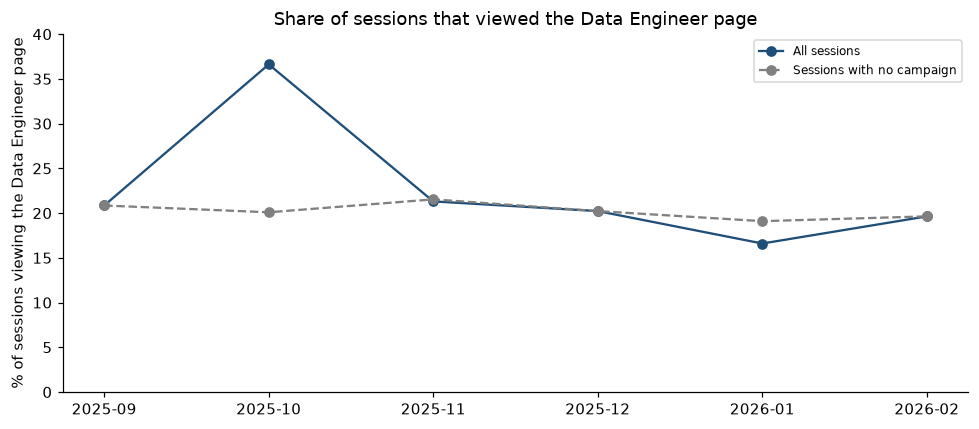

Share of sessions viewing the Data Engineer page (%):
         All sessions  No-campaign sessions
month                                      
2025-09          20.9                  20.9
2025-10          36.6                  20.1
2025-11          21.3                  21.5
2025-12          20.2                  20.2
2026-01          16.6                  19.1
2026-02          19.6                  19.6


In [7]:
# Interest in the Data Engineer role over time, with and without campaign sessions
def monthly_share(df, role):
    ids = set(role_pv.loc[role_pv["placement_role"] == role, "session_id"])
    return df.assign(v=df["session_id"].isin(ids)).groupby("month")["v"].mean() * 100

no_camp = eligible[eligible["campaign_id"] == "none"]
all_sessions = monthly_share(eligible, "Data Engineer")
no_campaign = monthly_share(no_camp, "Data Engineer")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(all_sessions.index, all_sessions.values, "-", marker="o", color="#1f4e79", label="All sessions")
ax.plot(no_campaign.index, no_campaign.values, "--", marker="o", color="grey", label="Sessions with no campaign")
ax.set_ylabel("% of sessions viewing the Data Engineer page"); ax.set_ylim(0, 40); ax.legend(fontsize=8)
ax.set_title("Share of sessions that viewed the Data Engineer page")
plt.tight_layout(); plt.savefig("../reports/figures/q2_role_interest.png", dpi=150); plt.show()

print("Share of sessions viewing the Data Engineer page (%):")
print(pd.DataFrame({"All sessions": all_sessions, "No-campaign sessions": no_campaign}).round(1).to_string())

**Findings (Q2)**

**Data Engineer was the most viewed role page.** It was viewed in about 4,860 sessions (25% of eligible sessions). Software Engineer was next with about 4,000 sessions. Some visitors look at more than one role, so the role numbers cannot be added together.

**Normal interest is steady at about 20%, and October was a campaign effect.** In October, the share of sessions that viewed the Data Engineer page rose from about 21% to about 37%, then went back to about 21% in November. Among sessions with no campaign, the share stayed between about 19% and 22% in every month. So the October jump came from the LinkedIn campaign, not from a general rise in interest.

**Data Engineer viewers are more likely to click Apply, but less likely to click Send Email.** About 20% of them clicked Apply, compared with about 12% of sessions that viewed no role page and 16.5% of all sessions. About 6% clicked Send Email, compared with about 9% of sessions that viewed no role page and 7.2% of all sessions. The no-role group includes people who go straight to the application page, who already have intent.

**Visitors from the Data Engineer campaign were even more likely to click Apply.** About 27.5% of them clicked Apply, compared with 16.5% of all sessions. Their Send Email rate (8.7%) was only a little above average (7.2%).

**This does not answer the original question directly.** The data has no Data Analyst page, so Data Engineer is used as a stand-in. Also, viewing a role page shows interest, but not which role someone will apply for. An application page view or an email click does not say which role the visitor wants.

## Defining an application-intent journey

I use **distinct sessions**, not events, and I do **not require a fixed order** for the main measure, because the dictionary says people can land directly on `/application`. I then check the order separately.

**Intent** = the session has at least one `application_email_click`. This is the main outcome.

**Supporting stages** (each counted once per session): viewed `/application`, and clicked Apply Now.

**Ordered path check:** among sessions with both clicks, did Apply come before Email?

In [8]:
app_viewers = set(page_views.loc[page_views["page_path"] == "/application", "session_id"])
apply_ids = set(elig_events.loc[elig_events["event_name"] == "apply_cta_click", "session_id"])
email_ids = set(elig_events.loc[elig_events["event_name"] == "application_email_click", "session_id"])

funnel = pd.Series({
    "Eligible sessions": len(eligible),
    "Viewed /application": len(app_viewers),
    "Clicked Apply Now (any page)": len(apply_ids),
    "Clicked Send Email": len(email_ids),
})
print((funnel.to_frame("sessions").assign(pct_of_eligible=(funnel / len(eligible) * 100).round(1))).to_string())
print()
print("Send Email clicks by page:", elig_events.loc[elig_events["event_name"] == "application_email_click", "page_path"].value_counts().to_dict())
print("Email-click sessions that never viewed /application:", len(email_ids - app_viewers))
print("Apply-click sessions that never viewed /application:", len(apply_ids - app_viewers), "of", len(apply_ids))
print("Share of /application viewers who clicked Send Email:", round(len(app_viewers & email_ids) / len(app_viewers), 3))

first = (elig_events[elig_events["event_timestamp_utc"].notna()].assign(t=lambda d: pd.to_datetime(d["event_timestamp_utc"]))
         .groupby(["session_id", "event_name"])["t"].min().unstack())
both = first.dropna(subset=["apply_cta_click", "application_email_click"])
print("\nSessions with both clicks:", len(both), "| Apply before Email:", int((both["apply_cta_click"] <= both["application_email_click"]).sum()))
print("Email clicks without an Apply click (direct path):", len(email_ids - apply_ids))
direct = eligible[eligible["landing_page_path"] == "/application"]
print("Sessions landing directly on /application:", len(direct), "| email click rate:", round(direct["has_email_click"].mean(), 3))
print("Sessions with more than one email click:", int((elig_events[elig_events["event_name"] == "application_email_click"].groupby("session_id").size() > 1).sum()))

                              sessions  pct_of_eligible
Eligible sessions                19398            100.0
Viewed /application               4071             21.0
Clicked Apply Now (any page)      3207             16.5
Clicked Send Email                1396              7.2

Send Email clicks by page: {'/application': 1487}
Email-click sessions that never viewed /application: 0
Apply-click sessions that never viewed /application: 210 of 3207
Share of /application viewers who clicked Send Email: 0.343

Sessions with both clicks: 1106 | Apply before Email: 1106
Email clicks without an Apply click (direct path): 290
Sessions landing directly on /application: 1107 | email click rate: 0.269
Sessions with more than one email click: 91


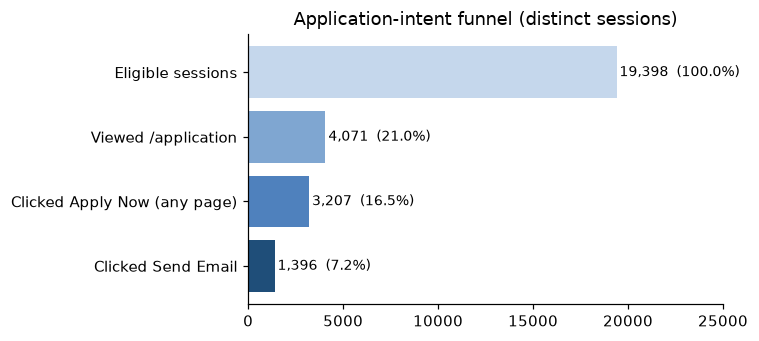

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(funnel.index[::-1], funnel.values[::-1], color=["#1f4e79", "#4f81bd", "#7fa6d1", "#c5d7ec"][::-1][::-1])
for i, v in enumerate(funnel.values[::-1]):
    ax.text(v + 150, i, f"{v:,}  ({v / len(eligible):.1%})", va="center", fontsize=9)
ax.set_xlim(0, 25000); ax.set_title("Application-intent funnel (distinct sessions)")
plt.tight_layout(); plt.savefig("../reports/figures/journey_funnel.png", dpi=150); plt.show()

**Findings (journey)**

**About 7.2% of eligible sessions clicked Send Email.** About 21% viewed the application page, and about a third of those (34%) then clicked Send Email.

**The data fits together logically.** Every email click happened on the `/application` page, and every session with an email click had viewed that page. In all sessions with both clicks, the Apply click came before the Email click.

**About 290 sessions clicked Send Email without clicking Apply.** These visitors came another way. Many probably went straight to the application page, as about 1,100 sessions did, and 27% of those clicked Send Email.

**About 210 sessions clicked Apply but never viewed `/application`.** This could be a link opened in a new tab, or a tracking problem, so I treat it as a limitation. It is also a reason not to require a strict order of steps.

# Question 3: Unusual periods and segments
For each one I decided to list the evidence that points to **real behaviour** or to a **data or tracking problem**.

### 3.1) 14 to 16 January 2026: a burst of sessions from `traffic-check.example` (data issue)

                        suspected automated  all other sessions
sessions                             1350.0             19398.0
unique visitors                      1350.0             14782.0
% desktop                             100.0                42.1
% landed on home page                 100.0                38.9
page views per session                  1.0                 1.9
% with a click                          0.0                18.0

sessions per day: {Timestamp('2026-01-14 00:00:00'): 450, Timestamp('2026-01-15 00:00:00'): 450, Timestamp('2026-01-16 00:00:00'): 450}
countries: {'US': 930, 'SG': 420}


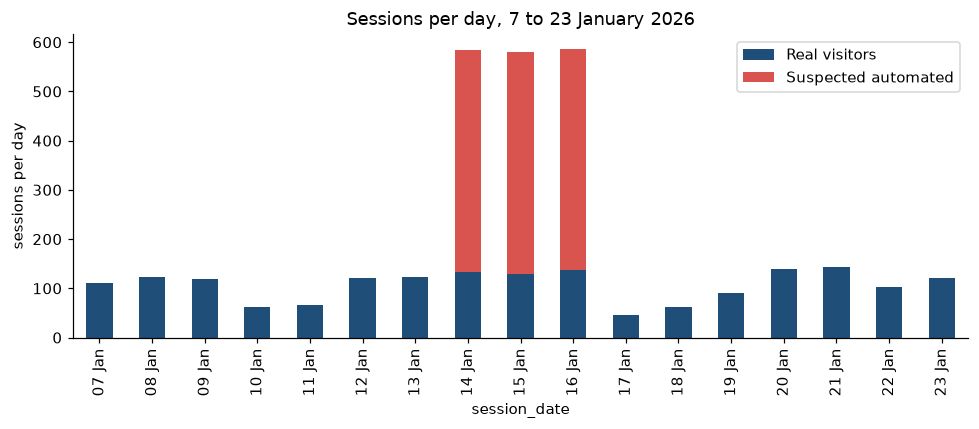

In [10]:
bot = sessions[sessions["is_suspected_automated"]]
rest = sessions[~sessions["is_suspected_automated"]]

# Compare the suspicious sessions with all other sessions
def facts(df):
    return pd.Series({
        "sessions": len(df),
        "unique visitors": df["visitor_id"].nunique(),
        "% desktop": (df["device_category"] == "desktop").mean() * 100,
        "% landed on home page": (df["landing_page_path"] == "/").mean() * 100,
        "page views per session": df["page_views"].mean(),
        "% with a click": (df["has_apply_click"] | df["has_email_click"]).mean() * 100,
    })

print(pd.DataFrame({"suspected automated": facts(bot), "all other sessions": facts(rest)}).round(1))
print("\nsessions per day:", bot.groupby("session_date").size().to_dict())
print("countries:", bot["country_code"].value_counts().to_dict())

# Chart: sessions per day around the spike
window = sessions[(sessions["session_date"] >= "2026-01-07") & (sessions["session_date"] <= "2026-01-23")]
per_day = window.groupby(["session_date", "is_suspected_automated"]).size().unstack(fill_value=0)
per_day.columns = ["Real visitors", "Suspected automated"]
per_day.index = per_day.index.strftime("%d %b")
per_day.plot(kind="bar", stacked=True, color=["#1f4e79", "#d9534f"], figsize=(9, 4))
plt.ylabel("sessions per day"); plt.title("Sessions per day, 7 to 23 January 2026")
plt.tight_layout(); plt.savefig("../reports/figures/q3_automated_traffic.png", dpi=150); plt.show()

**Evidence:** exactly 450 sessions on each of 3 days, all from one source, all desktop, all from the US or Singapore, all landing on the home page, every one with a single page view, no clicks at all, and a different visitor ID each time. Real visitors vary far more than that. **My opinion**: most likely automated or test traffic. I excluded it from rates instead of deleting it. If it were included, tracked sessions on those three days would look about 4 times higher (about 580 instead of about 135 per day) and the email click rate would fall on those days.

### 3.2) 6 to 24 October: the Data Engineer campaign boost (real behaviour, linked to a campaign)

In [11]:
window = eligible[(eligible["session_date"] >= "2025-10-06") & (eligible["session_date"] <= "2025-10-24")]
camp = eligible[eligible["campaign_id"] == "CMP-DE-OCT"]
def summary(df):
    return pd.Series({"sessions": len(df), "% landing on Data Engineer page": (df["landing_page_path"] == "/roles/data-engineer").mean() * 100,
                      "% mobile": (df["device_category"] == "mobile").mean() * 100,
                      "apply click rate %": df["has_apply_click"].mean() * 100, "email click rate %": df["has_email_click"].mean() * 100})
print(pd.DataFrame({"CMP-DE-OCT sessions": summary(camp),
                    "other sessions, same dates": summary(window[window["campaign_id"] == "none"]),
                    "all eligible sessions": summary(eligible)}).round(1).to_string())
base = eligible[(eligible["campaign_id"] == "none")]
print("\nAvg non-campaign sessions/day: September", round(base[base["session_date"] < "2025-10-01"].groupby("session_date").size().mean()),
      "| 6-24 Oct", round(base[(base["session_date"] >= "2025-10-06") & (base["session_date"] <= "2025-10-24")].groupby("session_date").size().mean()))

                                 CMP-DE-OCT sessions  other sessions, same dates  all eligible sessions
sessions                                      1521.0                      2743.0                19398.0
% landing on Data Engineer page                 76.3                         8.4                   13.6
% mobile                                        55.1                        54.6                   54.1
apply click rate %                              27.5                        17.0                   16.5
email click rate %                               8.7                         7.9                    7.2

Avg non-campaign sessions/day: September 91 | 6-24 Oct 144


**Evidence:** campaign-tagged sessions are concentrated on the Data Engineer page (76%), arrive mostly via LinkedIn/Social, and are more likely to click Apply (about 27.5% versus about 16.5% overall). Their email click rate (8.7%) is only slightly above average. **My opinion**: real behaviour, linked to the campaign. It is also important to mention that **non-campaign traffic also rose** (about 91 sessions/day in September to about 144 during the campaign window), so something else (for example, seasonal application interest) may also be involved.

### 3.3) Desktop versus mobile: a large gap in application intent (preference issue)

                 sessions  apply_rate  viewed_application  email_rate  email_rate_among_application_viewers
device_category                                                                                            
desktop              8164        21.4                25.5        10.3                                  40.3
mobile              10504        13.0                17.7         5.0                                  28.1
tablet                730        13.4                17.8         4.8                                  26.9

                  share of sessions %  share of email-click sessions %
device_category                                                      
desktop                         42.1                             60.1
mobile                          54.1                             37.4
tablet                           3.8                              2.5

Email click rate % by channel and device:
device_category  desktop  mobile  tablet
channel                 

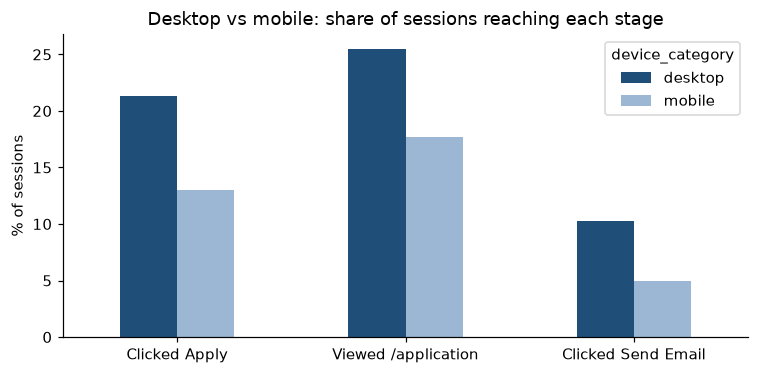

In [12]:
app_view = eligible["session_id"].isin(app_viewers)
dev = eligible.assign(viewed_app=app_view).groupby("device_category").agg(
    sessions=("session_id", "size"), apply_rate=("has_apply_click", "mean"),
    viewed_application=("viewed_app", "mean"), email_rate=("has_email_click", "mean"))
dev["email_rate_among_application_viewers"] = eligible[app_view].groupby("device_category")["has_email_click"].mean()
print((dev * [1, 100, 100, 100, 100]).round(1).to_string())
share = pd.DataFrame({"share of sessions %": eligible["device_category"].value_counts(normalize=True) * 100,
                      "share of email-click sessions %": eligible[eligible["has_email_click"]]["device_category"].value_counts(normalize=True) * 100}).round(1)
print("\n", share.to_string())
print("\nEmail click rate % by channel and device:")
print((eligible.pivot_table(index="channel", columns="device_category", values="has_email_click", aggfunc="mean") * 100).round(1).to_string())
app_time = page_views[page_views["page_path"] == "/application"].merge(eligible[["session_id", "device_category"]], on="session_id")
print("\nAverage active seconds on /application, by device:", app_time.groupby("device_category")["engagement_seconds"].mean().round(1).to_dict())
x = dev[["apply_rate", "viewed_application", "email_rate"]].loc[["desktop", "mobile"]] * 100
x.columns = ["Clicked Apply", "Viewed /application", "Clicked Send Email"]
x.T.plot(kind="bar", figsize=(7, 3.5), rot=0, color=["#1f4e79", "#9bb7d4"]); plt.ylabel("% of sessions"); plt.title("Desktop vs mobile: share of sessions reaching each stage")
plt.tight_layout(); plt.savefig("../reports/figures/q3_device_gap.png", dpi=150); plt.show()

**Evidence:** desktop sessions click Send Email about **10%** of the time versus about **5%** on mobile, and the gap is present **in every channel and at every stage** (Apply click, viewing `/application`, and Send Email among those who viewed it). Time spent on `/application` is almost the same on both (about 29 seconds). Mobile is 54% of sessions but only 37% of email-click sessions. **My opinion**: users prefer to apply and fill out the forms using bigger screens and comfortable keyboards, for which Desktop is more suitable than Mobile.

# Question 4: Recommendations

**1. Run role-specific campaigns for the other roles, starting with Technical Analyst.**
*Evidence:* the Data Engineer campaign brought a large, focused audience whose Apply click rate was about 27.5% versus 16.5% overall (section 3.2). The Technical Analyst page gets steady but modest interest (about 14% of sessions) and has no targeted campaign.

**2. Look into the mobile application experience.**
*Evidence:* mobile is 54% of sessions but 37% of email-click sessions and the gap exists at every stage (section 3.3). The reasons are hard to determine with current data, but my logical assumption would be an uncomfortable user experience.

**3. Stop automated traffic from entering the reports and monitor for it.**
*Evidence:* on 14 to 16 January, 1,350 sessions arrived from one source (`traffic-check.example`), exactly 450 a day. All were on desktop, all came from the US or Singapore, all landed on the home page, each had one page view and no clicks and every one had a different visitor ID (section 3.1). On those three days the tracked sessions were 580 a day, but only about 135 a day were real visitors. Left in, this traffic would make the site look about four times busier and would push the Send Email rate down.